In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
digits = load_digits()
df = pd.DataFrame(digits.data)
df['Target'] = digits.target
print(df.head())

     0    1    2     3     4     5  ...    59    60    61   62   63  Target
0  0.0  0.0  5.0  13.0   9.0   1.0  ...  13.0  10.0   0.0  0.0  0.0       0
1  0.0  0.0  0.0  12.0  13.0   5.0  ...  11.0  16.0  10.0  0.0  0.0       1
2  0.0  0.0  0.0   4.0  15.0  12.0  ...   3.0  11.0  16.0  9.0  0.0       2
3  0.0  0.0  7.0  15.0  13.0   1.0  ...  13.0  13.0   9.0  0.0  0.0       3
4  0.0  0.0  0.0   1.0  11.0   0.0  ...   2.0  16.0   4.0  0.0  0.0       4

[5 rows x 65 columns]


In [ ]:
X = digits.data
y = digits.target

print("Shape of dataset:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))

Shape of dataset: (1797, 64)
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

Original shape: (1797, 64)
Scaled shape: (1797, 64)


In [ ]:
inertia = []
silhouette_scores = []

k_values = range(2, 16)

for k in k_values:


    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )


    labels = kmeans.fit_predict(X_scaled)


    inertia.append(kmeans.inertia_)


    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

print("Experiment completed.")

Experiment completed.


In [ ]:
results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia,
    "Silhouette Score": silhouette_scores
})

print(results)

     K        Inertia  Silhouette Score
0    2  100423.843034          0.105638
1    3   93842.482749          0.105287
2    4   89213.968157          0.095386
3    5   85096.054668          0.102298
4    6   81678.466699          0.098789
5    7   77749.327896          0.113494
6    8   74854.159172          0.126590
7    9   72029.725334          0.135985
8   10   69813.559137          0.139377
9   11   67261.847461          0.153194
10  12   65031.723728          0.154325
11  13   62763.180754          0.156527
12  14   61963.418696          0.156195
13  15   59534.498937          0.158307


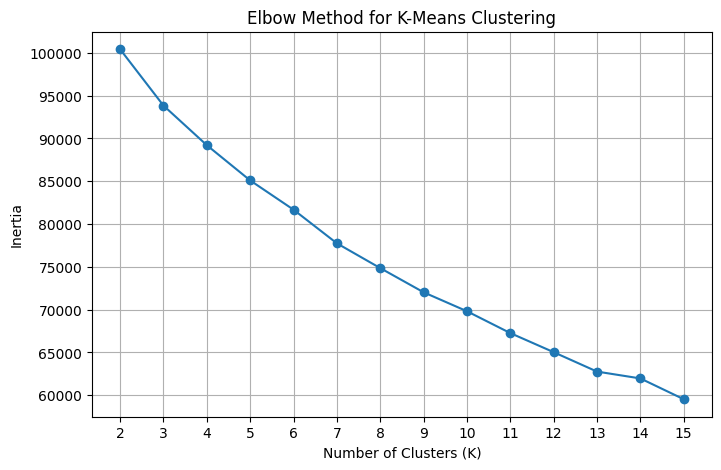

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")

plt.xticks(k_values)
plt.grid(True)

plt.show()

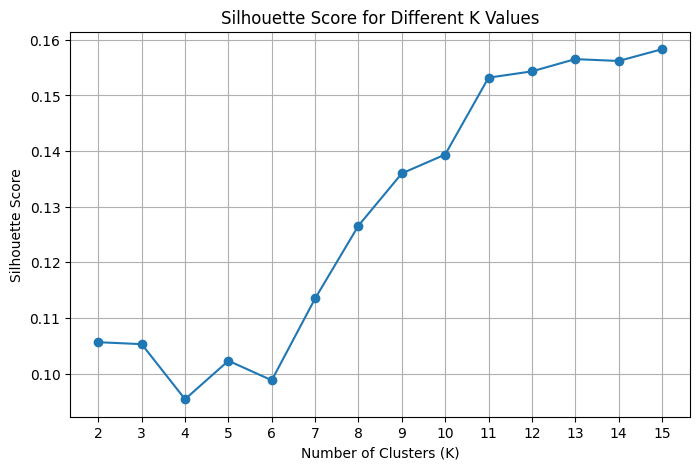

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_scores, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(k_values)
plt.grid(True)

plt.show()

In [ ]:
best_index = np.argmax(silhouette_scores)

best_k = list(k_values)[best_index]
best_score = silhouette_scores[best_index]

print("Best K:", best_k)
print("Highest Silhouette Score:", best_score)

Best K: 15
Highest Silhouette Score: 0.15830708064242807


In [ ]:
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_final.fit_predict(X_scaled)

print("Cluster labels:")
print(cluster_labels[:20])

Cluster labels:
[ 6  1  1  3 10  3  5  4  3  3  6  2  9  3 10  7  5  4  1  3]


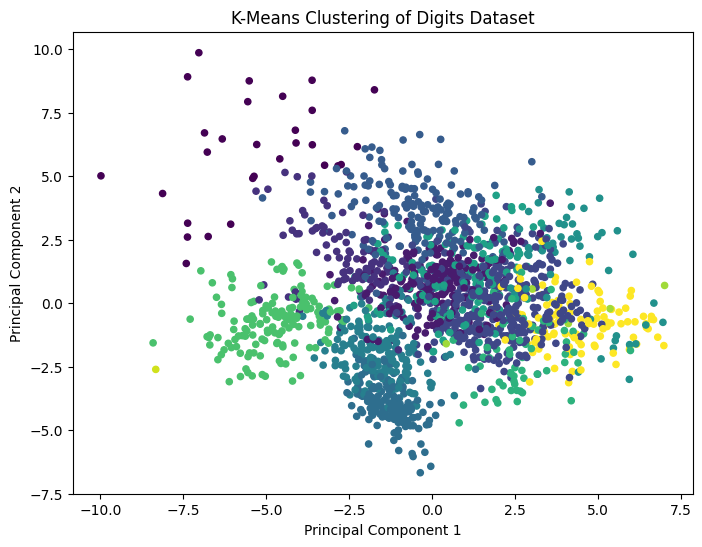

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    s=20
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Digits Dataset")

plt.show()